<a href="https://colab.research.google.com/github/eliezana05/-DI-Bootcamp-Stage1/blob/main/Week3/Day3/Apple/Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Dataset: Apple Stock Prices (1981 to 2023).csv (10608, 7)


,Date,Open,High,Low,Close,Adj Close,Volume
0,02/01/1981,0.154018,0.155134,0.154018,0.154018,0.119849,21660800
1,05/01/1981,0.151228,0.151228,0.150670,0.150670,0.117244,35728000
2,06/01/1981,0.144531,0.144531,0.143973,0.143973,0.112032,45158400
3,07/01/1981,0.138393,0.138393,0.137835,0.137835,0.107256,55686400
4,08/01/1981,0.135603,0.135603,0.135045,0.135045,0.105085,39827200


,dtype
Date,object
Open,float64
High,float64
Low,float64
Close,float64
Adj Close,float64
Volume,int64


,Missing
Date,0
Open,0
High,0
Low,0
Close,0
Adj Close,0
Volume,0


Date range: 1981-01-02 00:00:00 2023-01-27 00:00:00 Rows: 10608
Calendar-day gaps: date
1 days    8317
3 days    1927
4 days     265
2 days      95
5 days       2
Name: count, dtype: int64
Observations are trading days: weekends and exchange holidays create gaps; missing dates are not filled with invented trades.


,mean,median,std
open,1.668917e+01,4.888390e-01,3.545052e+01
high,1.687996e+01,4.955360e-01,3.588285e+01
low,1.650082e+01,4.804465e-01,3.503129e+01
close,1.669736e+01,4.877010e-01,3.547391e+01
adj_close,1.602735e+01,4.048505e-01,3.515488e+01
volume,3.275098e+08,2.145976e+08,3.378203e+08


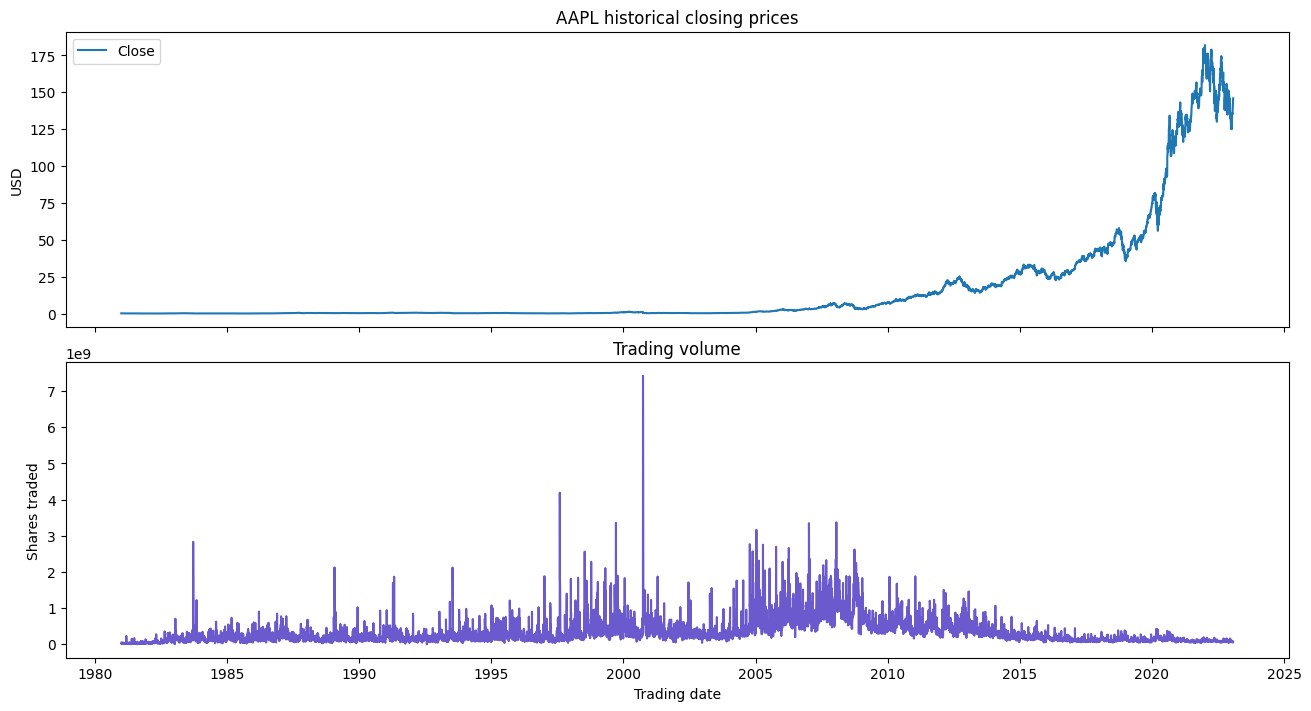

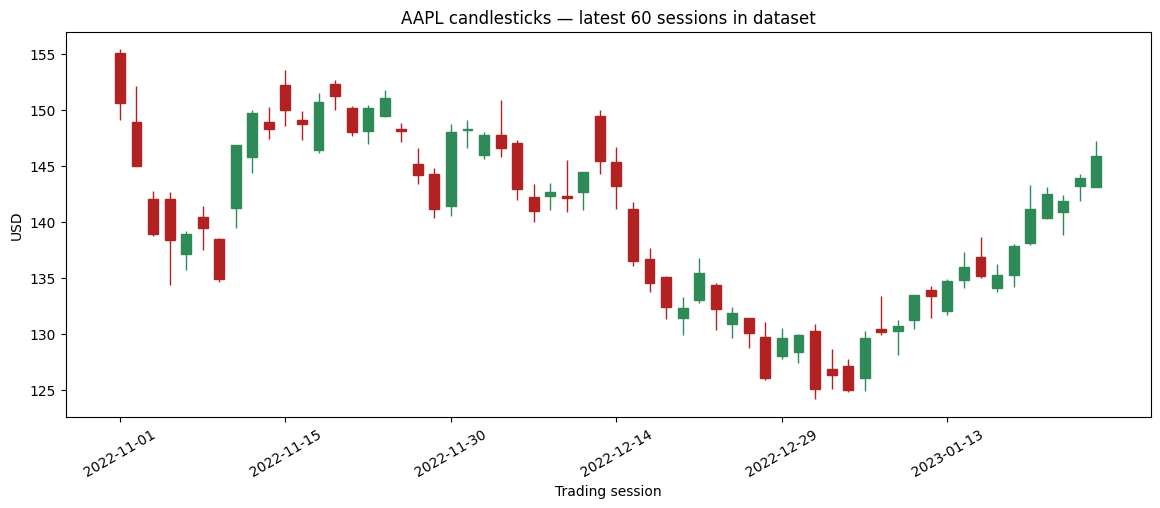

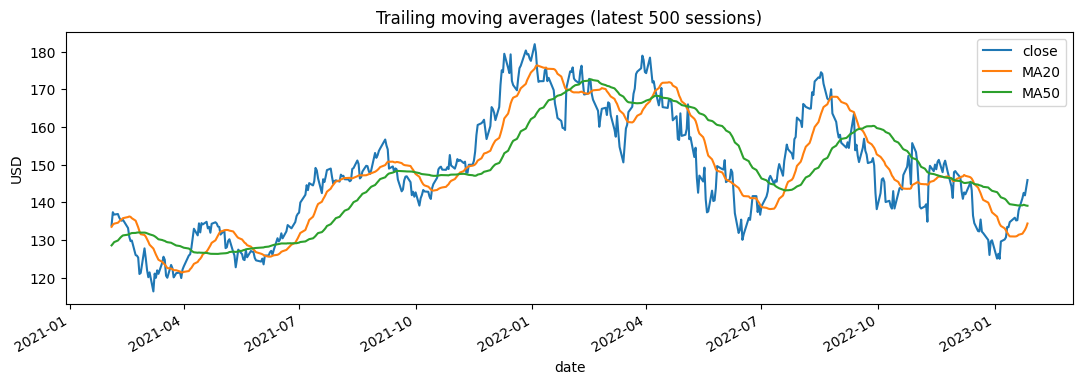

Welch yearly closing-price comparison: [2021, 2022] Means: 140.98936516269842 154.83505970119523 Test: TtestResult(statistic=np.float64(-11.18656637005918), pvalue=np.float64(4.7097114017662864e-26), df=np.float64(494.8624386319599))
Return basis: adj_close n= 10607 Mean: 0.0010754479489290924 Median: 0.0 Std: 0.02823256291515543
Normality H0: Gaussian daily returns; DAgostino-Pearson result: NormaltestResult(statistic=np.float64(2721.3868085536874), pvalue=np.float64(0.0))


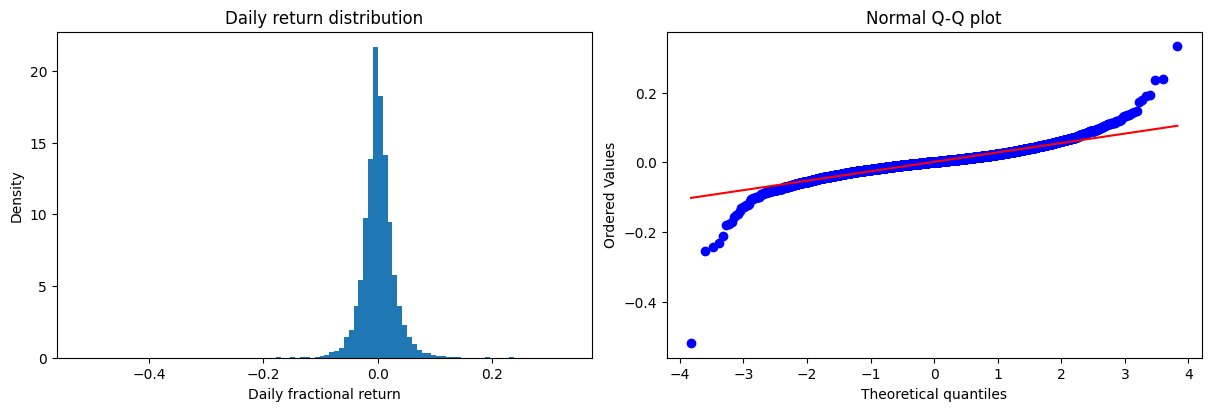

Correlation MA20 price vs MA20 volume: -0.26568492991563075


,Year,Price-volume rolling correlation
33,2014,-0.655475
34,2015,-0.319976
35,2016,-0.401680
36,2017,0.053532
37,2018,-0.140820
38,2019,-0.562195
39,2020,-0.348581
40,2021,-0.177267
41,2022,0.066478
42,2023,0.221751


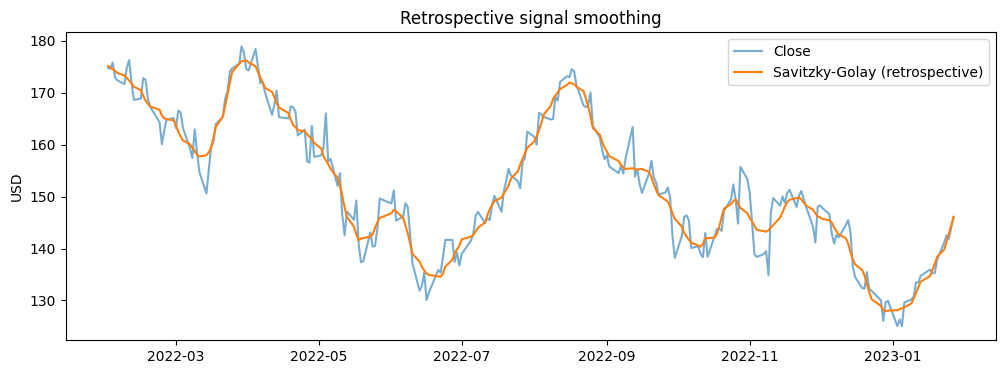

## Summary and insights
- Dataset covers 1981-01-02 to 2023-01-27, with 10,608 retained trading-day records.
- Mean closing prices: 2021 = 140.99 USD, 2022 = 154.84 USD. Welch p=4.71e-26. Serial dependence and changing price levels limit this test's interpretation.
- Daily returns use **adj_close**. Mean=0.1075%, standard deviation=2.8233%. Normality-test p=0: reject Gaussianity at 5%. Large samples can detect small departures; Q-Q plots help assess tail behavior.
- Twenty-session averages from NumPy convolution agree with Pandas rolling averages. Rolling price-volume correlation is -0.266; this association does not establish a causal relationship.
- Moving averages smooth daily movements. The candlestick chart preserves each session's open, high, low and close rather than only its endpoint.

## Reflection: implementation challenges and solutions
- Trading calendars are irregular: dates were sorted and duplicates removed, without filling holidays as observations.
- Corporate actions distort unadjusted return comparisons: adjusted close is used when available and the choice is printed explicitly.
- Rolling-window alignment is easy to shift: NumPy and Pandas results were compared numerically.
- Statistical significance can be misleading for stock-price levels: temporal dependence, non-stationarity and descriptive-only conclusions are stated alongside the required t-test.
- Two-sided smoothing can leak future information: Savitzky-Golay output is labeled retrospective.


Apple analysis validation checks passed.


In [2]:
# Mini-project — Advanced Statistical Analysis of Apple Stock Data
# Octopus chapter 3421; historical course dataset, not live prices.
import io, zipfile, requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from scipy import stats, signal
from IPython.display import display, Markdown

url='https://github.com/devtlv/Datasets-GEN-AI-Bootcamp/raw/refs/heads/main/Week%203/W3D4%20-%20Mini%20Project/Apple%20Stock%20Prices%20From%201981%20to%202023.zip'
r=requests.get(url,timeout=90); r.raise_for_status()
z=zipfile.ZipFile(io.BytesIO(r.content))
csvs=[n for n in z.namelist() if n.endswith('.csv') and '__MACOSX' not in n]
assert len(csvs)==1,csvs
raw=pd.read_csv(z.open(csvs[0]))
print('Dataset:',csvs[0],raw.shape); display(raw.head(),raw.dtypes.to_frame('dtype'),raw.isna().sum().to_frame('Missing'))
raw.columns=[c.strip().lower().replace(' ','_') for c in raw.columns]
raw['date']=pd.to_datetime(raw['date'],format='%d/%m/%Y',errors='raise',utc=True).dt.tz_localize(None)
for c in ['open','high','low','close','adj_close','volume']:
    if c in raw:
        raw[c]=pd.to_numeric(raw[c],errors='coerce')
df=raw.dropna(subset=['date','open','high','low','close','volume']).drop_duplicates('date').sort_values('date').set_index('date')
df=df.loc[(df.close>0)&(df.open>0)&(df.volume>=0)].copy()
assert len(df)==len(raw), 'Unexpected dropped price rows'
print('Date range:',df.index.min(),df.index.max(),'Rows:',len(df))
print('Calendar-day gaps:',df.index.to_series().diff().value_counts().head())
print('Observations are trading days: weekends and exchange holidays create gaps; missing dates are not filled with invented trades.')
display(df.select_dtypes('number').agg(['mean','median','std']).T)

fig,axes=plt.subplots(2,1,figsize=(13,7),sharex=True,constrained_layout=True)
axes[0].plot(df.index,df.close,label='Close'); axes[0].set(ylabel='USD',title='AAPL historical closing prices'); axes[0].legend()
axes[1].plot(df.index,df.volume,color='slateblue'); axes[1].set(ylabel='Shares traded',xlabel='Trading date',title='Trading volume'); plt.show()
# Candles of latest 60 sessions; wicks show low-high, body shows open-close.
recent=df.tail(60); fig,ax=plt.subplots(figsize=(14,5))
for i,(_,row) in enumerate(recent.iterrows()):
    color='seagreen' if row.close>=row.open else 'firebrick'
    ax.vlines(i,row.low,row.high,color=color,linewidth=1)
    height=abs(row.close-row.open)
    if height==0:
        ax.hlines(row.close,i-.3,i+.3,color=color)
    else:
        ax.add_patch(Rectangle((i-.3,min(row.open,row.close)),.6,height,color=color))
positions=np.arange(0,len(recent),10)
ax.set_xticks(positions,[recent.index[i].strftime('%Y-%m-%d') for i in positions],rotation=30)
ax.set(title='AAPL candlesticks — latest 60 sessions in dataset',xlabel='Trading session',ylabel='USD'); ax.autoscale_view(); plt.show()

# Trailing averages use only current and preceding observations.
df['MA20']=df.close.rolling(20,min_periods=20).mean()
df['MA50']=df.close.rolling(50,min_periods=50).mean()
np_ma=np.convolve(df.close.to_numpy(),np.ones(20)/20,mode='valid')
np.testing.assert_allclose(np_ma,df.MA20.dropna().to_numpy(),rtol=1e-10)
fig,ax=plt.subplots(figsize=(13,4)); df[['close','MA20','MA50']].tail(500).plot(ax=ax); ax.set(title='Trailing moving averages (latest 500 sessions)',ylabel='USD'); plt.show()

# Per assignment: Welch t-test comparing the last two years with >=200 sessions.
# Closing levels are autocorrelated and non-stationary; independent-sample t-test
# assumptions are doubtful. Treat p-values as descriptive, not trading evidence.
year_counts=df.groupby(df.index.year).size(); years=year_counts[year_counts>=200].index[-2:]
assert len(years)==2
a=df.loc[df.index.year==years[0],'close'].to_numpy(); b=df.loc[df.index.year==years[1],'close'].to_numpy()
year_test=stats.ttest_ind(a,b,equal_var=False)
print('Welch yearly closing-price comparison:',years.tolist(),'Means:',a.mean(),b.mean(),'Test:',year_test)

# Adjusted prices are preferred for returns to account for corporate actions.
return_col='adj_close' if 'adj_close' in df.columns else 'close'
prices=df[return_col].where(df[return_col]>0)
returns=prices.pct_change(fill_method=None).replace([np.inf,-np.inf],np.nan).dropna()
normal=stats.normaltest(returns.to_numpy())
print('Return basis:',return_col,'n=',len(returns),'Mean:',np.mean(returns),'Median:',np.median(returns),'Std:',np.std(returns,ddof=1))
print('Normality H0: Gaussian daily returns; DAgostino-Pearson result:',normal)
fig,axes=plt.subplots(1,2,figsize=(12,4),constrained_layout=True)
axes[0].hist(returns,bins=100,density=True); axes[0].set(title='Daily return distribution',xlabel='Daily fractional return',ylabel='Density')
stats.probplot(returns,dist='norm',plot=axes[1]); axes[1].set_title('Normal Q-Q plot'); plt.show()

# Bonus: correlation of rolling price average and rolling volume per year.
# Correlation of trending levels does not show causality.
rolling_volume=df.volume.rolling(20,min_periods=20).mean()
valid=df.MA20.notna()&rolling_volume.notna()
correlation=np.corrcoef(df.loc[valid,'MA20'],rolling_volume[valid])[0,1]
print('Correlation MA20 price vs MA20 volume:',correlation)
yearly_corr=[]
for year,group in df.loc[valid].groupby(df.loc[valid].index.year):
    vol=rolling_volume.loc[group.index]
    if len(group)>2 and group.MA20.std()>0 and vol.std()>0:
        yearly_corr.append([year,np.corrcoef(group.MA20,vol)[0,1]])
display(pd.DataFrame(yearly_corr,columns=['Year','Price-volume rolling correlation']).tail(10))
# Savitzky-Golay smoothing is two-sided and uses future neighboring values.
# It is for retrospective visualization and must not be used as a live signal.
subset=df.close.tail(250); smoothed=signal.savgol_filter(subset.to_numpy(),21,2)
fig,ax=plt.subplots(figsize=(12,4)); ax.plot(subset.index,subset,label='Close',alpha=.6); ax.plot(subset.index,smoothed,label='Savitzky-Golay (retrospective)'); ax.legend(); ax.set(title='Retrospective signal smoothing',ylabel='USD'); plt.show()

summary=f'''## Summary and insights
- Dataset covers {df.index.min().date()} to {df.index.max().date()}, with {len(df):,} retained trading-day records.
- Mean closing prices: {years[0]} = {a.mean():.2f} USD, {years[1]} = {b.mean():.2f} USD. Welch p={year_test.pvalue:.3g}. Serial dependence and changing price levels limit this test's interpretation.
- Daily returns use **{return_col}**. Mean={returns.mean():.4%}, standard deviation={returns.std():.4%}. Normality-test p={normal.pvalue:.3g}: {'reject' if normal.pvalue<.05 else 'do not reject'} Gaussianity at 5%. Large samples can detect small departures; Q-Q plots help assess tail behavior.
- Twenty-session averages from NumPy convolution agree with Pandas rolling averages. Rolling price-volume correlation is {correlation:.3f}; this association does not establish a causal relationship.
- Moving averages smooth daily movements. The candlestick chart preserves each session's open, high, low and close rather than only its endpoint.

## Reflection: implementation challenges and solutions
- Trading calendars are irregular: dates were sorted and duplicates removed, without filling holidays as observations.
- Corporate actions distort unadjusted return comparisons: adjusted close is used when available and the choice is printed explicitly.
- Rolling-window alignment is easy to shift: NumPy and Pandas results were compared numerically.
- Statistical significance can be misleading for stock-price levels: temporal dependence, non-stationarity and descriptive-only conclusions are stated alongside the required t-test.
- Two-sided smoothing can leak future information: Savitzky-Golay output is labeled retrospective.
'''
display(Markdown(summary))
assert df.index.is_monotonic_increasing and df.index.is_unique
assert (df.high>=df.low).all()
assert np.isfinite(returns).all()
print('Apple analysis validation checks passed.')
